<div align="center">

# ¿Quién compite por los contratos públicos en Boyacá?
## Contratación directa vs. contratación competitiva en SECOP II (2022–2026)

**Universidad Santo Tomás – Seccional Tunja · Ingeniería de Sistemas**
**Big Data 2026-2 · Proyecto Integrador (Corte 3)**

</div>

| | |
|---|---|
| **Integrantes** | Sebastian Gonzalo Ayala Garcia · Santiago Andres Avila Suarez · Gabriel Felipe Bastidas Alvarado |
| **Tema** | Uso de la contratación directa frente a las modalidades competitivas en las entidades públicas de Boyacá |
| **Dataset** | *SECOP II – Contratos Electrónicos* (Colombia Compra Eficiente, datos.gov.co, ID `jbjy-vk9h`), filtrado a `departamento = 'Boyacá'` y `fecha_de_firma ≥ 2022-01-01` |
| **Registros / columnas** | 124.434 contratos · 29 columnas (descarga del 9 de noviembre de 2026) |
| **Temáticas aplicadas** | PySpark · MongoDB · Streaming (Spark Structured Streaming) · Visualización (NumPy, Matplotlib, Seaborn, Plotly) |

## 2. Contexto y preguntas de análisis

**El problema en tres frases**

1. **Problema:** en Colombia la regla general es que el Estado contrate por modalidades competitivas (licitación, selección abreviada, mínima cuantía, concurso de méritos), y la contratación directa es la excepción; sin embargo, en las entidades de Boyacá no existe una forma sencilla de ver cuánto del gasto se adjudica sin competencia.
2. **A quién afecta:** a las **veedurías ciudadanas, concejos y asamblea departamental, periodistas locales y entes de control**, que necesitan priorizar qué entidades revisar, y a los **proveedores** que quieren competir por contratos públicos.
3. **Qué responde el análisis:** cuánto pesa la contratación directa, en qué entidades y tipos de contrato se concentra, cómo cambia en el tiempo y si la Ley de Garantías la reduce.

**Conceptos clave**

- **Contratación directa:** la entidad escoge al contratista sin convocatoria pública (Ley 1150 de 2007, art. 2 num. 4). Es legal en causales específicas, como la prestación de servicios profesionales y de apoyo a la gestión o los convenios interadministrativos.
- **Régimen especial:** entidades que no se rigen por el Estatuto General (por ejemplo, Empresas Sociales del Estado – hospitales, empresas de servicios públicos). Se analizan como un grupo aparte porque no son directamente comparables.
- **Ley de Garantías (Ley 996 de 2005):** en los cuatro meses previos a la elección presidencial y hasta la segunda vuelta, las entidades **no pueden contratar directamente**. En el periodo analizado hubo dos ventanas: **29 ene – 19 jun 2022** y **31 ene – 21 jun 2026**.

**Preguntas de análisis**

| # | Pregunta |
|---|---|
| **P1** | ¿Qué proporción del número y del valor de los contratos se adjudica por contratación directa frente a las modalidades competitivas, y cómo evoluciona entre 2022 y 2026? |
| **P2** | ¿Qué entidades —entre las de mayor gasto— dependen más de la contratación directa? |
| **P3** | ¿La contratación directa cae durante la Ley de Garantías y se recupera después (efecto "represa")? |
| **P4** | ¿Qué tipos de contrato y de proveedor explican la contratación directa, y cuánto se concentra en pocos proveedores? |

In [1]:
# Librerías y configuración general
import os, warnings, hashlib, unicodedata, time, shutil, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")
import sys
pio.renderers.default = "colab" if "google.colab" in sys.modules else "notebook_connected"   # Colab necesita su propio renderizador

RUTA_RAW = "data/secop_boyaca_2022_2026.csv"
RUTA_LIMPIO = "data/contratos_limpio.parquet"
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.4


## 3. Carga de datos y diagnóstico de calidad

El archivo se obtuvo desde la API pública (Socrata) de datos.gov.co con esta consulta, que filtra en el servidor para no descargar los millones de contratos de todo el país. Se seleccionaron 29 de las ~90 columnas originales; **se excluyeron a propósito las columnas con datos personales que no aportan al análisis** (cuentas bancarias, cédulas de supervisores y ordenadores del gasto).

```
https://www.datos.gov.co/resource/jbjy-vk9h.csv
   ?$select=<29 columnas>
   &$where=departamento='Boyacá' AND fecha_de_firma>='2022-01-01T00:00:00'
   &$limit=200000
```

In [2]:
raw = pd.read_csv(RUTA_RAW, low_memory=False)
print(f"Filas: {raw.shape[0]:,} | Columnas: {raw.shape[1]}")
print(f"Memoria en pandas: {raw.memory_usage(deep=True).sum()/1e6:,.1f} MB")
raw.head(3)

Filas: 124,434 | Columnas: 29
Memoria en pandas: 102.3 MB


,nombre_entidad,nit_entidad,departamento,ciudad,orden,sector,rama,proceso_de_compra,id_contrato,estado_contrato,codigo_de_categoria_principal,descripcion_del_proceso,tipo_de_contrato,modalidad_de_contratacion,justificacion_modalidad_de,fecha_de_firma,fecha_de_inicio_del_contrato,fecha_de_fin_del_contrato,tipodocproveedor,documento_proveedor,proveedor_adjudicado,es_pyme,origen_de_los_recursos,destino_gasto,valor_del_contrato,valor_facturado,valor_pagado,dias_adicionados,duraci_n_del_contrato
0,MUNICIPIO DE DUITAMA,891855138,Boyacá,Duitama,Territorial,Servicio Público,Ejecutivo,CO1.BDOS.2809198,CO1.PCCNTR.3553906,Cerrado,V1.80111620,PRESTACION DE SERVICIOS COMO PROMOTOR DEPORTIV...,Prestación de servicios,Contratación directa,Servicios profesionales y apoyo a la gestión,2022-02-02T19:50:16.900,2022-02-14T08:00:00.000,2022-07-13T23:59:00.000,Cédula de Ciudadanía,1052382050,EDGAR HELY ROJAS PENAGOS,No,Distribuido,Inversión,"7,680,000.00",0.00,0.00,0,5 Mes(es)
1,MUNICIPIO DE DUITAMA,891855138,Boyacá,Duitama,Territorial,Servicio Público,Ejecutivo,CO1.BDOS.8654342,CO1.PCCNTR.8250353,En ejecución,V1.80111620,PRESTACIÓN DE SERVICIOS PROFESIONALES PARA EL ...,Prestación de servicios,Contratación directa,Servicios profesionales y apoyo a la gestión,2025-08-28T17:15:15.950,2025-08-29T08:00:00.000,2025-12-28T20:00:00.000,Cédula de Ciudadanía,1057580345,EDHY ALEXANDRA CARDONA CORREDOR,No,Distribuido,Inversión,"14,320,000.00",0.00,0.00,0,4 Mes(es)
2,ALCALDIA MUNICIPIO DE ARCABUCO,800063791,Boyacá,No Definido,Nacional,Servicio Público,Ejecutivo,CO1.BDOS.7585758,CO1.PCCNTR.7465662,En ejecución,V1.80111620,PRESTACION DE SERVICIOS DE APOYO A LA GESTION ...,Prestación de servicios,Contratación directa,Servicios profesionales y apoyo a la gestión,2025-02-12T10:33:50.376,2025-02-12T12:00:00.000,2025-12-31T23:00:00.000,NIT,900924966,ENLINEA.APP SAS,Si,Distribuido,Inversión,"7,150,000.00","7,150,000.00","7,150,000.00",0,321 Dia(s)


In [3]:
# Tipos de dato inferidos: las fechas llegan como texto y deben convertirse
tipos = pd.DataFrame({"tipo": raw.dtypes.astype(str),
                      "valores_unicos": raw.nunique(),
                      "ejemplo": raw.iloc[0]})
tipos

,tipo,valores_unicos,ejemplo
nombre_entidad,str,393,MUNICIPIO DE DUITAMA
nit_entidad,int64,357,891855138
departamento,str,1,Boyacá
ciudad,str,115,Duitama
orden,str,3,Territorial
sector,str,19,Servicio Público
rama,str,4,Ejecutivo
proceso_de_compra,str,120308,CO1.BDOS.2809198
id_contrato,str,124434,CO1.PCCNTR.3553906
estado_contrato,str,7,Cerrado


In [4]:
# Nulos explícitos (NaN) y nulos "disfrazados" ("No Definido", "No definido", "Sin Descripcion")
DISFRAZADOS = {"no definido", "sin descripcion", "no aplica", ""}
nulos = pd.DataFrame({
    "nulos_NaN": raw.isna().sum(),
    "nulos_disfrazados": raw.apply(lambda s: s.astype(str).str.strip().str.lower().isin(DISFRAZADOS).sum()
                                    if s.dtype == object or str(s.dtype) == "str" else 0),
})
nulos["%_total"] = (nulos.sum(axis=1) / len(raw) * 100).round(2)
nulos[nulos[["nulos_NaN", "nulos_disfrazados"]].sum(axis=1) > 0].sort_values("%_total", ascending=False)

,nulos_NaN,nulos_disfrazados,%_total
ciudad,0,7820,6.28
fecha_de_inicio_del_contrato,1420,0,1.14
destino_gasto,0,493,0.40
documento_proveedor,0,283,0.23
descripcion_del_proceso,0,252,0.20
tipodocproveedor,0,174,0.14
justificacion_modalidad_de,0,8,0.01
proveedor_adjudicado,0,11,0.01


In [5]:
# Duplicados: filas completas y por identificador de contrato
print("Filas duplicadas exactas      :", raw.duplicated().sum())
print("id_contrato duplicados        :", raw["id_contrato"].duplicated().sum())

# Problemas de consistencia en los valores
v = raw["valor_del_contrato"]
print("Contratos con valor = 0       :", (v == 0).sum())
print("Contratos con 0 < valor < $10.000:", v.between(0.001, 9_999).sum())
print("Contratos con valor > $50.000 M:", (v > 5e10).sum())
print("Fecha de firma mínima / máxima:", raw["fecha_de_firma"].min(), "/", raw["fecha_de_firma"].max())

# Estados con mayúsculas inconsistentes y nombres de entidad sin estandarizar
print("\nestado_contrato:", raw["estado_contrato"].unique().tolist())
print("Ejemplos de nombres de entidad en minúscula:",
      raw.loc[raw["nombre_entidad"].str.islower(), "nombre_entidad"].unique()[:5].tolist())

Filas duplicadas exactas      : 0
id_contrato duplicados        : 0
Contratos con valor = 0       : 676
Contratos con 0 < valor < $10.000: 82
Contratos con valor > $50.000 M: 14
Fecha de firma mínima / máxima: 2022-01-01T12:32:24.797 / 2026-11-05T12:04:41.718

estado_contrato: ['Cerrado', 'En ejecución', 'terminado', 'Modificado', 'Aprobado', 'cedido', 'Suspendido']
Ejemplos de nombres de entidad en minúscula: ['sutamarchan']


In [6]:
# Los 10 contratos de mayor valor: revisión manual de posibles errores de digitación
cols = ["nombre_entidad", "modalidad_de_contratacion", "tipo_de_contrato", "valor_del_contrato", "descripcion_del_proceso"]
top = raw.nlargest(10, "valor_del_contrato")[cols].copy()
top["descripcion_del_proceso"] = top["descripcion_del_proceso"].str.slice(0, 70)
top["valor (miles de millones)"] = top.pop("valor_del_contrato") / 1e9
top

,nombre_entidad,modalidad_de_contratacion,tipo_de_contrato,descripcion_del_proceso,valor (miles de millones)
57636,GOBERNACIÓN DE BOYACÁ,Selección abreviada subasta inversa,Suministros,SUMINISTRO DE ELEMENTOS Y EQUIPOS PARA ALMACEN...,"2,385.62"
116571,ALCALDÍA MUNICIPAL DE TIPACOQUE,Contratación régimen especial (con ofertas),Decreto 092 de 2017,AUNAR ESFUERZOS TÉCNICOS; ADMINISTRATIVOS; ECO...,431.34
20729,ALCALDÍA MUNICIPAL DE AQUITANIA,Contratación directa,Otro,CONVENIO INTERADMINISTRATIVO CON EL FONDO MIXT...,299.76
32860,sutamarchan,Contratación directa,Prestación de servicios,Aunar esfuerzos técnicos; administrativos y fi...,286.72
68535,ALCALDIA MUNICIPAL DE MIRAFLORES BOYACA,Contratación directa,Otro,CONVENIO SOLIDARIO ENTRE EL MUNICIPIO DE MIRAF...,122.87
104952,GOBERNACIÓN DE BOYACÁ,Contratación directa,Operaciones de Crédito Público,BANCOLOMBIA ha acordado prestar a EL DEUDOR ha...,85.44
50540,MUNICIPIO DE MOTAVITA,Contratación régimen especial,Prestación de servicios,CONVENIO DE ASOCIACIÓN CON EL CUERPO DE BOMBER...,74.40
89693,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN RAFAEL ...,Contratación régimen especial (con ofertas),Prestación de servicios,PRESTACIÓN DE SERVICIOS PROFESIONALES Y DE APO...,72.86
44278,GOBERNACIÓN DE BOYACÁ,Contratación Directa (con ofertas),Obra,AUNAR ESFUERZOS ENTRE EL DEPARTAMENTO DE BOYAC...,70.27
373,EMPRESA SOCIAL DEL ESTADO HOSPITAL SAN RAFAEL ...,Contratación régimen especial (con ofertas),Prestación de servicios,PRESTACIÓN DE SERVICIOS PROFESIONALES Y DE APO...,67.61


**Hallazgos del diagnóstico**

- **Sin duplicados:** ni filas repetidas ni `id_contrato` repetidos, así que cada fila es un contrato único.
- **Tipos:** las tres fechas llegan como texto (`str`) y deben convertirse a `datetime`. `nit_entidad` es numérico, pero es un identificador, no una cantidad.
- **Nulos:** el único nulo explícito importante es `fecha_de_inicio_del_contrato`. El problema mayor son los **nulos disfrazados**: `ciudad = "No Definido"` en miles de contratos y campos como `es_pyme` o `origen_de_los_recursos` con "No Definido".
- **Valores inválidos:** 676 contratos con valor $0 y unos 80 con valores simbólicos de centavos o $1, que no son montos reales.
- **Valores extremos:** unos pocos contratos superan los $50.000 millones. La revisión manual muestra casos imposibles para su objeto (un suministro de elementos de almacenamiento por **$2,4 billones**, más que el presupuesto anual del departamento), un **crédito bancario** registrado como contrato y convenios de municipios pequeños por cientos de miles de millones. Si se dejan, distorsionan cualquier suma de valor.
- **Inconsistencias de texto:** estados con mayúsculas mezcladas (`terminado` / `Cerrado`) y nombres de entidad escritos de varias formas.

## 4. Limpieza y transformación

Cada decisión se justifica a continuación:

| Decisión | Justificación |
|---|---|
| Convertir las 3 fechas a `datetime` y crear `anio`, `mes`, `anio_mes` | Las preguntas P1 y P3 son temporales. |
| Estandarizar texto (sin tildes, mayúsculas, espacios, símbolos sueltos) en entidad, ciudad y proveedor | La misma entidad aparece escrita de varias formas ("MUNICIPIO DE TUNJA/", "sutamarchan") y eso partiría sus totales. |
| Unificar el nombre de cada entidad por su **NIT** (el nombre más frecuente) | Hay más nombres que NIT: una misma entidad legal figura con varios nombres. El NIT es el identificador confiable. |
| Reemplazar "No Definido" / "Sin Descripcion" por `NaN` | Son nulos reales; tratarlos como categoría inflaría falsos grupos. |
| Crear `grupo_modalidad` (Directa / Competitiva / Régimen especial) | Es la variable central del análisis. "Directa (con ofertas)" sigue siendo directa; régimen especial se separa porque obedece a normas propias. |
| Marcar `valor_cero` (valor < \$10.000) y **excluir esos contratos solo de los cálculos de valor** | Un contrato de \$0, \$0,01 o \$1 (comodatos y arriendos simbólicos) no es un monto real, pero sí cuenta como contrato. |
| Marcar `valor_extremo` (> \$50.000 millones) y excluirlo de los cálculos de valor | La revisión manual mostró errores de digitación y operaciones no comparables. Son 14 contratos (0,01 %), pero suman más que todo el resto. Se conservan en los conteos. |
| Crear `ley_garantias` | Permite responder P3 comparando dentro y fuera de las ventanas restrictivas. |
| Crear `tipo_proveedor` (Persona natural / Persona jurídica) a partir del tipo de documento | Ayuda a explicar P4: la directa suele contratar personas naturales. |
| Eliminar `documento_proveedor` y dejar un identificador seudonimizado (hash) | Es la cédula de personas naturales; para el análisis basta con un identificador estable y así se protege el dato personal. |

In [7]:
df = raw.copy()

# 1) Fechas
for c in ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")
df["anio"] = df["fecha_de_firma"].dt.year
df["mes"] = df["fecha_de_firma"].dt.month
df["anio_mes"] = df["fecha_de_firma"].dt.to_period("M").dt.to_timestamp()

# 2) Texto estandarizado
def normalizar(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return " ".join(s.upper().split())

for c in ["nombre_entidad", "ciudad", "proveedor_adjudicado"]:
    df[c] = df[c].map(normalizar)
df["nombre_entidad"] = df["nombre_entidad"].str.rstrip("/+*.- ")          # símbolos sueltos al final ("TUNJA/", "TOCA*")
df["estado_contrato"] = df["estado_contrato"].str.strip().str.capitalize()

# Una entidad = un NIT: se usa como nombre el más frecuente de cada NIT,
# porque la misma entidad aparece registrada con nombres distintos
df["nombre_entidad_original"] = df["nombre_entidad"]
nombre_canonico = df.groupby("nit_entidad")["nombre_entidad"].agg(lambda s: s.value_counts().index[0])
df["nombre_entidad"] = df["nit_entidad"].map(nombre_canonico)

# 3) Nulos disfrazados -> NaN
df = df.replace({"No Definido": np.nan, "No definido": np.nan, "NO DEFINIDO": np.nan,
                 "Sin Descripcion": np.nan, "Sin Descripción": np.nan})

# 4) Grupo de modalidad
def grupo(m):
    m = str(m).lower()
    if "directa" in m:
        return "Directa"
    if "régimen especial" in m or "regimen especial" in m:
        return "Régimen especial"
    return "Competitiva"
df["grupo_modalidad"] = df["modalidad_de_contratacion"].map(grupo)

# 5) Banderas de calidad del valor
df["valor_cero"] = df["valor_del_contrato"] < 10_000          # $0 o simbólicos ($0,01, $1 ...)
df["valor_extremo"] = df["valor_del_contrato"] > 5e10
df["valor_valido"] = ~(df["valor_cero"] | df["valor_extremo"])
df["valor_analisis"] = np.where(df["valor_valido"], df["valor_del_contrato"], np.nan)

# 6) Ley de Garantías (restricción a la contratación directa)
VENTANAS = [("2022-01-29", "2022-06-19"), ("2026-01-31", "2026-06-21")]
df["ley_garantias"] = False
for ini, fin in VENTANAS:
    df.loc[df["fecha_de_firma"].between(ini, f"{fin} 23:59:59"), "ley_garantias"] = True

# 7) Tipo de proveedor y seudonimización del documento
df["tipo_proveedor"] = np.where(df["tipodocproveedor"].str.contains("Ciudadan|Extranjer|Pasaporte", na=False),
                                "Persona natural", "Persona jurídica")
df["id_proveedor"] = df["documento_proveedor"].fillna("SIN_DOCUMENTO").astype(str).map(lambda x: hashlib.sha256(x.encode()).hexdigest()[:12])
df = df.drop(columns=["documento_proveedor"])

# Validaciones de la limpieza
assert df["id_contrato"].is_unique
assert df["fecha_de_firma"].notna().all()
print(df["grupo_modalidad"].value_counts())
print("\nContratos excluidos del análisis de valor:",
      int((~df['valor_valido']).sum()), f"({(~df['valor_valido']).mean()*100:.2f} %)")
print("Contratos firmados en Ley de Garantías:", int(df["ley_garantias"].sum()))

grupo_modalidad
Directa             89104
Competitiva         20363
Régimen especial    14967
Name: count, dtype: int64

Contratos excluidos del análisis de valor: 772 (0.62 %)
Contratos firmados en Ley de Garantías: 6164


In [8]:
# Antes vs. después: tamaño y nulos de las columnas clave
resumen = pd.DataFrame({
    "antes": [raw["nombre_entidad"].nunique(), raw["estado_contrato"].nunique(),
              f'"No Definido": {raw["ciudad"].eq("No Definido").sum():,}', len(raw)],
    "despues": [df["nombre_entidad"].nunique(), df["estado_contrato"].nunique(),
                f'NaN: {df["ciudad"].isna().sum():,}', int(df["valor_valido"].sum())],
}, index=["entidades distintas", "estados de contrato distintos", "ciudad sin definir",
          "contratos usados en sumas de valor"])
display(resumen)

df.to_parquet(RUTA_LIMPIO, index=False)
print(f"Dataset limpio guardado en {RUTA_LIMPIO}: {df.shape[0]:,} filas x {df.shape[1]} columnas "
      f"({os.path.getsize(RUTA_LIMPIO)/1e6:,.1f} MB)")

,antes,despues
entidades distintas,393,357
estados de contrato distintos,7,7
ciudad sin definir,"""No Definido"": 7,820","NaN: 7,820"
contratos usados en sumas de valor,124434,123662


Dataset limpio guardado en data/contratos_limpio.parquet: 124,434 filas x 40 columnas (21.9 MB)


## 5. Procesamiento y análisis

Se aplican **cuatro** temáticas del curso:

1. **PySpark:** lectura, filtros, `groupBy`, Spark SQL y un *join*, verificados con `count()`.
2. **MongoDB:** carga de una parte de los datos, consultas con operadores y un *pipeline* de agregación.
3. **Streaming:** Spark Structured Streaming simula la llegada mensual de contratos y actualiza una métrica.
4. **Visualización:** NumPy, Matplotlib, Seaborn y Plotly (sección 6).

### 5.1 PySpark

In [9]:
from pyspark.sql import SparkSession, functions as F, Window
import platform

# En Windows, Spark Streaming necesita winutils.exe y hadoop.dll (ver README)
if platform.system() == "Windows" and os.path.exists(r"C:\hadoop\bin"):
    os.environ["HADOOP_HOME"] = r"C:\hadoop"
    os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]


spark = (SparkSession.builder
         .appName("SECOP_Boyaca")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.driver.memory", "3g")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Spark 4.3.0


In [10]:
# Lectura del CSV crudo con Spark: multiLine porque las descripciones traen saltos de línea
sdf_raw = (spark.read
           .option("header", True)
           .option("multiLine", True)
           .option("escape", '"')
           .option("inferSchema", True)
           .csv(RUTA_RAW))
n_spark = sdf_raw.count()
print(f"Filas leídas por Spark: {n_spark:,} | coincide con pandas: {n_spark == len(raw)}")
sdf_raw.select("nombre_entidad", "modalidad_de_contratacion", "valor_del_contrato", "fecha_de_firma").show(3, truncate=40)

Filas leídas por Spark: 124,434 | coincide con pandas: True
+------------------------------+-------------------------+------------------+-----------------------+
|                nombre_entidad|modalidad_de_contratacion|valor_del_contrato|         fecha_de_firma|
+------------------------------+-------------------------+------------------+-----------------------+
|          MUNICIPIO DE DUITAMA|     Contratación directa|         7680000.0|  2022-02-02 19:50:16.9|
|          MUNICIPIO DE DUITAMA|     Contratación directa|           1.432E7| 2025-08-28 17:15:15.95|
|ALCALDIA MUNICIPIO DE ARCABUCO|     Contratación directa|         7150000.0|2025-02-12 10:33:50.376|
+------------------------------+-------------------------+------------------+-----------------------+
only showing top 3 rows


In [11]:
# Se trabaja sobre el dataset limpio (parquet) para no repetir la limpieza
sdf = spark.read.parquet(RUTA_LIMPIO)
print("Filas del parquet limpio:", f"{sdf.count():,}")

# Filtro 1: solo contratos con valor válido
sdf_valor = sdf.filter(F.col("valor_valido"))
print("Con valor válido        :", f"{sdf_valor.count():,}")

# Filtro 2: contratación directa de prestación de servicios
sdf_ps = sdf.filter((F.col("grupo_modalidad") == "Directa") & (F.col("tipo_de_contrato") == "Prestación de servicios"))
print("Directa + prest. serv.  :", f"{sdf_ps.count():,}")

Filas del parquet limpio: 124,434
Con valor válido        : 123,662
Directa + prest. serv.  : 82,032


In [12]:
# groupBy: P1 — participación por año y grupo de modalidad
p1 = (sdf.groupBy("anio", "grupo_modalidad")
         .agg(F.count("*").alias("contratos"),
              F.sum("valor_analisis").alias("valor"))
         .withColumn("pct_contratos", F.round(100 * F.col("contratos") / F.sum("contratos").over(Window.partitionBy("anio")), 1))
         .withColumn("pct_valor", F.round(100 * F.col("valor") / F.sum("valor").over(Window.partitionBy("anio")), 1))
         .orderBy("anio", "grupo_modalidad"))
p1.withColumn("valor_mm", F.round(F.col("valor") / 1e9, 1)).drop("valor").show(20)

# Verificación con count(): la suma de los grupos debe dar el total
total_grupos = p1.agg(F.sum("contratos")).first()[0]
print("Verificación: suma de contratos en los grupos =", f"{total_grupos:,}", "| total =", f"{sdf.count():,}")

+----+----------------+---------+-------------+---------+--------+
|anio| grupo_modalidad|contratos|pct_contratos|pct_valor|valor_mm|
+----+----------------+---------+-------------+---------+--------+
|2022|     Competitiva|     2128|         14.5|     39.5|   486.9|
|2022|         Directa|    11281|         76.7|     36.3|   447.8|
|2022|Régimen especial|     1292|          8.8|     24.2|   298.3|
|2023|     Competitiva|     2884|         14.5|     29.7|   572.3|
|2023|         Directa|    14381|         72.2|     40.0|   770.0|
|2023|Régimen especial|     2653|         13.3|     30.3|   583.9|
|2024|     Competitiva|     4916|         17.1|     26.7|   583.8|
|2024|         Directa|    20584|         71.8|     36.0|   787.4|
|2024|Régimen especial|     3181|         11.1|     37.2|   813.2|
|2025|     Competitiva|     5828|         18.5|     24.7|   894.7|
|2025|         Directa|    21650|         68.8|     43.1|  1562.9|
|2025|Régimen especial|     3996|         12.7|     32.2|  116

In [13]:
# Spark SQL: P2 — entidades con mayor % de valor en contratación directa (solo entidades con >= $20.000 M)
sdf.createOrReplaceTempView("contratos")
p2 = spark.sql('''
    SELECT nombre_entidad,
           COUNT(*)                                                         AS contratos,
           ROUND(SUM(valor_analisis) / 1e9, 1)                              AS valor_total_mm,
           ROUND(100 * SUM(CASE WHEN grupo_modalidad = 'Directa' THEN valor_analisis ELSE 0 END)
                 / SUM(valor_analisis), 1)                                  AS pct_valor_directa,
           ROUND(100 * AVG(CASE WHEN grupo_modalidad = 'Directa' THEN 1 ELSE 0 END), 1) AS pct_contratos_directa
    FROM contratos
    WHERE valor_valido
    GROUP BY nombre_entidad
    HAVING SUM(valor_analisis) >= 2e10
    ORDER BY pct_valor_directa DESC
''')
print("Entidades con >= $20.000 M contratados:", p2.count())
p2.show(15, truncate=45)

Entidades con >= $20.000 M contratados: 66
+---------------------------------------------+---------+--------------+-----------------+---------------------+
|                               nombre_entidad|contratos|valor_total_mm|pct_valor_directa|pct_contratos_directa|
+---------------------------------------------+---------+--------------+-----------------+---------------------+
|                        GOBERNACION DE BOYACA|    19831|        2696.4|             68.6|                 95.6|
|                                        ITBOY|      830|          26.3|             62.6|                 81.4|
| ALCALDIA MUNICIPAL DE PUERTO BOYACA - BOYACA|     3507|         479.5|             62.2|                 75.6|
|SENA REGIONAL BOYACA GRUPO DE APOYO ADMINI...|     7117|         359.3|             59.5|                 86.2|
|                                  CORPOBOYACA|     3961|         203.1|             59.4|                 93.5|
|                ALCALDIA MUNICIPIO DE GARAGOA|      

In [14]:
# JOIN: compara cada entidad consigo misma dentro y fuera de la Ley de Garantías (P3)
dentro = (sdf.filter(F.col("ley_garantias"))
             .groupBy("nombre_entidad")
             .agg(F.count("*").alias("n_lg"),
                  F.round(100 * F.avg((F.col("grupo_modalidad") == "Directa").cast("int")), 1).alias("pct_directa_lg")))
fuera = (sdf.filter(~F.col("ley_garantias") & F.col("anio").isin(2022, 2026))
            .groupBy("nombre_entidad")
            .agg(F.count("*").alias("n_fuera"),
                 F.round(100 * F.avg((F.col("grupo_modalidad") == "Directa").cast("int")), 1).alias("pct_directa_fuera")))

comparacion = (dentro.join(fuera, on="nombre_entidad", how="inner")
                     .filter((F.col("n_lg") >= 30) & (F.col("n_fuera") >= 30))
                     .withColumn("diferencia_pp", F.round(F.col("pct_directa_lg") - F.col("pct_directa_fuera"), 1))
                     .orderBy("diferencia_pp"))
print("Entidades en ambos periodos (>= 30 contratos en cada uno):", comparacion.count())
comparacion.show(10, truncate=45)
print("Diferencia promedio (puntos porcentuales):",
      round(comparacion.agg(F.avg("diferencia_pp")).first()[0], 1))

Entidades en ambos periodos (>= 30 contratos en cada uno): 56
+---------------------------------------------+----+--------------+-------+-----------------+-------------+
|                               nombre_entidad|n_lg|pct_directa_lg|n_fuera|pct_directa_fuera|diferencia_pp|
+---------------------------------------------+----+--------------+-------+-----------------+-------------+
|                          MUNICIPIO DE SAMACA|  44|           2.3|    384|             94.5|        -92.2|
|                                        ITBOY|  35|           2.9|    343|             93.6|        -90.7|
|                        MUNICIPIO DE SOGAMOSO| 112|           0.0|   2102|             89.7|        -89.7|
|                           MUNICIPIO DE PAIPA| 103|           1.0|    831|             88.1|        -87.1|
|              ALCALDIA MUNICIPIO DE MONIQUIRA|  32|           0.0|    251|             86.5|        -86.5|
|                            MUNICIPIO DE TUTA|  45|           0.0|    215

In [15]:
# P4 — ¿qué tipos de contrato y proveedor explican la directa?
p4 = (sdf.filter(F.col("grupo_modalidad") == "Directa")
         .groupBy("tipo_de_contrato", "tipo_proveedor")
         .agg(F.count("*").alias("contratos"), F.round(F.sum("valor_analisis") / 1e9, 1).alias("valor_mm"))
         .withColumn("pct_contratos", F.round(100 * F.col("contratos") / F.sum("contratos").over(Window.partitionBy()), 1))
         .orderBy(F.desc("contratos")))
p4.show(8, truncate=35)

+--------------------------+----------------+---------+--------+-------------+
|          tipo_de_contrato|  tipo_proveedor|contratos|valor_mm|pct_contratos|
+--------------------------+----------------+---------+--------+-------------+
|   Prestación de servicios| Persona natural|    78402|  1516.4|         88.0|
|                      Otro|Persona jurídica|     4848|  1748.5|          5.4|
|   Prestación de servicios|Persona jurídica|     3630|   548.2|          4.1|
|Arrendamiento de inmuebles| Persona natural|      942|    36.0|          1.1|
|                      Obra|Persona jurídica|      343|   117.5|          0.4|
|Arrendamiento de inmuebles|Persona jurídica|      335|    35.7|          0.4|
|                  Comodato|Persona jurídica|      257|    NULL|          0.3|
|                      Otro| Persona natural|      139|     9.2|          0.2|
+--------------------------+----------------+---------+--------+-------------+
only showing top 8 rows


In [16]:
# Se pasan a pandas solo los resultados agregados (pequeños) para graficar
p1_pd = p1.toPandas()
p2_pd = p2.toPandas()
comp_pd = comparacion.toPandas()
p4_pd = p4.toPandas()
print(p1_pd.shape, p2_pd.shape, comp_pd.shape, p4_pd.shape)

(15, 6) (66, 5) (56, 6) (21, 5)


### 5.2 MongoDB

Se carga en MongoDB una **parte** de los datos —los contratos firmados en 2025 y 2026— como documentos, con un subdocumento `proveedor`. El notebook se conecta al servidor indicado en la variable de entorno `MONGO_URI` (por ejemplo, un MongoDB local o Atlas). Si no hay servidor disponible, usa `mongomock`, que emula la API de `pymongo` en memoria, para que el notebook siempre se pueda ejecutar de principio a fin.

In [17]:
import pymongo

MONGO_URI = os.environ.get("MONGO_URI", "mongodb://localhost:27017")
try:
    cliente = pymongo.MongoClient(MONGO_URI, serverSelectionTimeoutMS=2000)
    cliente.admin.command("ping")
    motor = f"MongoDB real ({MONGO_URI})"
except Exception:
    import mongomock
    cliente = mongomock.MongoClient()
    motor = "mongomock (emulación en memoria: no se encontró un servidor MongoDB)"
print("Conectado a:", motor)

db = cliente["secop_boyaca"]
col = db["contratos"]
col.drop()

parte = df[df["anio"] >= 2025].copy()
docs = [{
    "_id": r.id_contrato,
    "entidad": r.nombre_entidad,
    "ciudad": None if pd.isna(r.ciudad) else r.ciudad,
    "modalidad": r.modalidad_de_contratacion,
    "grupo_modalidad": r.grupo_modalidad,
    "tipo_contrato": r.tipo_de_contrato,
    "fecha_firma": r.fecha_de_firma.to_pydatetime(),
    "anio": int(r.anio),
    "valor": None if pd.isna(r.valor_analisis) else float(r.valor_analisis),
    "ley_garantias": bool(r.ley_garantias),
    "proveedor": {"id": r.id_proveedor, "nombre": r.proveedor_adjudicado, "tipo": r.tipo_proveedor},
} for r in parte.itertuples()]
res = col.insert_many(docs)
col.create_index([("entidad", 1), ("anio", 1)])
print(f"Documentos insertados: {len(res.inserted_ids):,} | count_documents: {col.count_documents({}):,}")
col.find_one({}, {"_id": 1, "entidad": 1, "grupo_modalidad": 1, "valor": 1, "proveedor": 1})

Conectado a: MongoDB real (mongodb://localhost:27017)
Documentos insertados: 61,134 | count_documents: 61,134


{'_id': 'CO1.PCCNTR.8250353',
 'entidad': 'MUNICIPIO DE DUITAMA',
 'grupo_modalidad': 'Directa',
 'valor': 14320000.0,
 'proveedor': {'id': 'd66333ca6a2b',
  'nombre': 'EDHY ALEXANDRA CARDONA CORREDOR',
  'tipo': 'Persona natural'}}

In [18]:
# Consultas con operadores
q1 = {"grupo_modalidad": "Directa", "valor": {"$gte": 1e9}}
print("Contratos directos de $1.000 M o más:", col.count_documents(q1))

q2 = {"modalidad": {"$in": ["Licitación pública", "Licitación pública Obra Publica"]}, "ciudad": "TUNJA"}
print("Licitaciones públicas en Tunja      :", col.count_documents(q2))

q3 = {"$and": [{"ley_garantias": True}, {"grupo_modalidad": "Directa"}]}
print("Directas firmadas en Ley de Garantías 2026:", col.count_documents(q3))

q4 = {"proveedor.tipo": "Persona jurídica", "grupo_modalidad": {"$ne": "Competitiva"}, "valor": {"$gt": 5e9}}
print("\nDirectas/régimen especial a personas jurídicas > $5.000 M (top 5):")
for d in col.find(q4, {"_id": 0, "entidad": 1, "proveedor.nombre": 1, "valor": 1}).sort("valor", -1).limit(5):
    print(f"  ${d['valor']/1e9:>7,.1f} mil M | {d['entidad'][:38]:38} | {d['proveedor']['nombre'][:40]}")

Contratos directos de $1.000 M o más: 225
Licitaciones públicas en Tunja      : 56
Directas firmadas en Ley de Garantías 2026: 247

Directas/régimen especial a personas jurídicas > $5.000 M (top 5):
  $   50.0 mil M | MUNICIPIO DE SOGAMOSO                  | BANCOLOMBIA
  $   37.6 mil M | MUNICIPIO DE SOGAMOSO                  | EMPRESA DE RENOVACION E INFRAESTRUCTURA 
  $   37.6 mil M | MUNICIPIO DE SOGAMOSO                  | EMPRESA DE RENOVACION E INFRAESTRUCTURA 
  $   33.1 mil M | GOBERNACION DE BOYACA                  | BANCOLOMBIA
  $   31.0 mil M | GOBERNACION DE BOYACA                  | BANCO DE OCCIDENTE SA


In [19]:
# Pipeline de agregación: concentración de proveedores (P4) por entidad, solo contratación directa
pipeline = [
    {"$match": {"grupo_modalidad": "Directa", "valor": {"$ne": None}}},
    {"$group": {"_id": {"entidad": "$entidad", "proveedor": "$proveedor.id"},
                "valor": {"$sum": "$valor"}}},
    {"$sort": {"valor": -1}},
    {"$group": {"_id": "$_id.entidad",
                "valor_total": {"$sum": "$valor"},
                "valor_top_proveedor": {"$first": "$valor"},
                "n_proveedores": {"$sum": 1}}},
    {"$match": {"valor_total": {"$gte": 5e9}}},
    {"$project": {"_id": 0, "entidad": "$_id", "n_proveedores": 1,
                  "valor_total_mm": {"$divide": ["$valor_total", 1e9]},
                  "pct_top_proveedor": {"$multiply": [{"$divide": ["$valor_top_proveedor", "$valor_total"]}, 100]}}},
    {"$sort": {"pct_top_proveedor": -1}},
    {"$limit": 10},
]
conc = pd.DataFrame(list(col.aggregate(pipeline)))
conc[["entidad", "n_proveedores", "valor_total_mm", "pct_top_proveedor"]].round(1)

,entidad,n_proveedores,valor_total_mm,pct_top_proveedor
0,ALCALDIA MUNICIPIO DE ARCABUCO,63,6.60,53.30
1,RAMA JUDICIAL DIRECCION SECCIONAL DE ADMINISTR...,48,11.10,52.10
2,ALCALDIA MUNICIPAL DE BRICENO BOYACA,70,5.30,44.40
3,MUNICIPIO DE CHITARAQUE,95,7.30,44.30
4,MUNICIPIO DE RAMIRIQUI,129,9.20,43.40
5,MUNICIPIO DE SOGAMOSO,828,239.90,39.30
6,ALCALDIA MUNICIPAL DE PUERTO BOYACA - BOYACA,372,126.40,37.90
7,MUNICIPIO DE TOCA,69,5.30,36.90
8,ALCALDIA MUNICIPAL DE NOBSA,233,26.20,35.90
9,MUNICIPIO DE TASCO,92,5.90,33.80


### 5.3 Streaming: llegada simulada de contratos

Para simular la llegada de datos, los contratos se reparten en **un archivo por mes** dentro de una carpeta. Spark Structured Streaming lee esa carpeta con `maxFilesPerTrigger = 1`, de modo que cada micro-lote equivale a "llega el mes siguiente". La métrica que se actualiza es el **% acumulado de contratos y de valor por contratación directa**, la que vería una veeduría en un tablero en vivo.

In [20]:
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, TimestampType

DIR_STREAM = "data/stream_entrada"
shutil.rmtree(DIR_STREAM, ignore_errors=True)
os.makedirs(DIR_STREAM)

# Se toman los 12 meses más recientes completos y se escribe un CSV por mes
ultimo_mes = df["anio_mes"].max()
meses = sorted(m for m in df["anio_mes"].unique() if m < ultimo_mes)[-12:]
cols_stream = ["id_contrato", "anio_mes", "grupo_modalidad", "valor_analisis"]
for i, m in enumerate(meses):
    lote = df.loc[df["anio_mes"] == m, cols_stream]
    lote.to_csv(f"{DIR_STREAM}/lote_{i:02d}_{m:%Y_%m}.csv", index=False)
print("Archivos de entrada:", len(os.listdir(DIR_STREAM)), "|", meses[0].strftime("%Y-%m"), "→", meses[-1].strftime("%Y-%m"))

esquema = StructType([StructField("id_contrato", StringType()),
                      StructField("anio_mes", TimestampType()),
                      StructField("grupo_modalidad", StringType()),
                      StructField("valor_analisis", DoubleType())])

Archivos de entrada: 12 | 2025-11 → 2026-10


In [21]:
flujo = (spark.readStream
         .schema(esquema)
         .option("header", True)
         .option("maxFilesPerTrigger", 1)      # 1 archivo (1 mes) por micro-lote
         .csv(DIR_STREAM))

# Métrica acumulada (outputMode complete): se recalcula con todo lo que ha llegado
metrica = (flujo.agg(F.count("*").alias("contratos"),
                     F.sum((F.col("grupo_modalidad") == "Directa").cast("int")).alias("directas"),
                     F.sum("valor_analisis").alias("valor"),
                     F.sum(F.when(F.col("grupo_modalidad") == "Directa", F.col("valor_analisis"))).alias("valor_directa"),
                     F.max("anio_mes").alias("ultimo_mes")))

historial = []
def registrar(lote_df, lote_id):
    r = lote_df.first()
    fila = {"lote": lote_id, "mes": r["ultimo_mes"], "contratos": r["contratos"],
            "pct_directa": 100 * r["directas"] / r["contratos"],
            "pct_valor_directa": 100 * r["valor_directa"] / r["valor"]}
    historial.append(fila)
    print(f"[lote {lote_id:02d}] llegó {fila['mes']:%Y-%m} | contratos acumulados: {fila['contratos']:>6,} | "
          f"% directa: {fila['pct_directa']:5.1f} % | % valor directa: {fila['pct_valor_directa']:5.1f} %")

CHECKPOINT = "data/stream_checkpoint"
shutil.rmtree(CHECKPOINT, ignore_errors=True)
consulta = (metrica.writeStream
            .outputMode("complete")
            .foreachBatch(registrar)
            .option("checkpointLocation", CHECKPOINT)
            .trigger(availableNow=True)
            .start())
consulta.awaitTermination()
hist = pd.DataFrame(historial)
print("\nMicro-lotes procesados:", len(hist))

[lote 00] llegó 2025-11 | contratos acumulados:  1,985 | % directa:  55.7 % | % valor directa:  65.2 %
[lote 01] llegó 2025-12 | contratos acumulados:  3,653 | % directa:  42.1 % | % valor directa:  39.2 %
[lote 02] llegó 2026-01 | contratos acumulados: 17,760 | % directa:  79.1 % | % valor directa:  43.2 %
[lote 03] llegó 2026-02 | contratos acumulados: 18,493 | % directa:  76.2 % | % valor directa:  40.3 %
[lote 04] llegó 2026-03 | contratos acumulados: 19,591 | % directa:  72.3 % | % valor directa:  35.7 %
[lote 05] llegó 2026-04 | contratos acumulados: 20,356 | % directa:  69.9 % | % valor directa:  35.1 %
[lote 06] llegó 2026-05 | contratos acumulados: 20,980 | % directa:  67.9 % | % valor directa:  32.6 %
[lote 07] llegó 2026-06 | contratos acumulados: 21,665 | % directa:  66.0 % | % valor directa:  31.8 %
[lote 08] llegó 2026-07 | contratos acumulados: 24,473 | % directa:  66.5 % | % valor directa:  31.3 %
[lote 09] llegó 2026-08 | contratos acumulados: 27,184 | % directa:  67.4

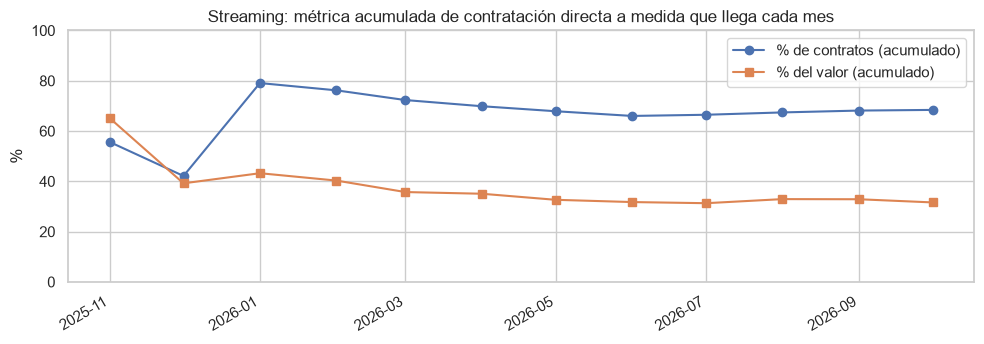

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hist["mes"], hist["pct_directa"], marker="o", label="% de contratos (acumulado)")
ax.plot(hist["mes"], hist["pct_valor_directa"], marker="s", label="% del valor (acumulado)")
ax.set_title("Streaming: métrica acumulada de contratación directa a medida que llega cada mes")
ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.legend(); fig.autofmt_xdate()
plt.tight_layout(); plt.show()

## 6. Visualizaciones que responden las preguntas

### NumPy: distribución de los valores por grupo de modalidad

In [23]:
vals = df.loc[df["valor_valido"], ["grupo_modalidad", "valor_analisis"]]
filas = []
for g, s in vals.groupby("grupo_modalidad")["valor_analisis"]:
    a = s.to_numpy()
    p25, p50, p75, p99 = np.percentile(a, [25, 50, 75, 99])
    filas.append({"grupo": g, "n": a.size, "media_M": a.mean()/1e6, "mediana_M": p50/1e6,
                  "p25_M": p25/1e6, "p75_M": p75/1e6, "p99_M": p99/1e6,
                  "coef_variacion": a.std()/a.mean(), "media_log10": np.log10(a).mean()})
stats = pd.DataFrame(filas).set_index("grupo")
stats.round(2)

,n,media_M,mediana_M,p25_M,p75_M,p99_M,coef_variacion,media_log10
grupo,,,,,,,,
Competitiva,20320,169.05,32.00,14.83,65.26,"2,289.18",6.92,7.53
Directa,88432,48.89,16.36,9.94,29.12,519.50,9.56,7.25
Régimen especial,14910,253.96,37.78,11.02,180.00,"3,269.06",4.18,7.65


### P1 · Participación de la contratación directa por año (Matplotlib)

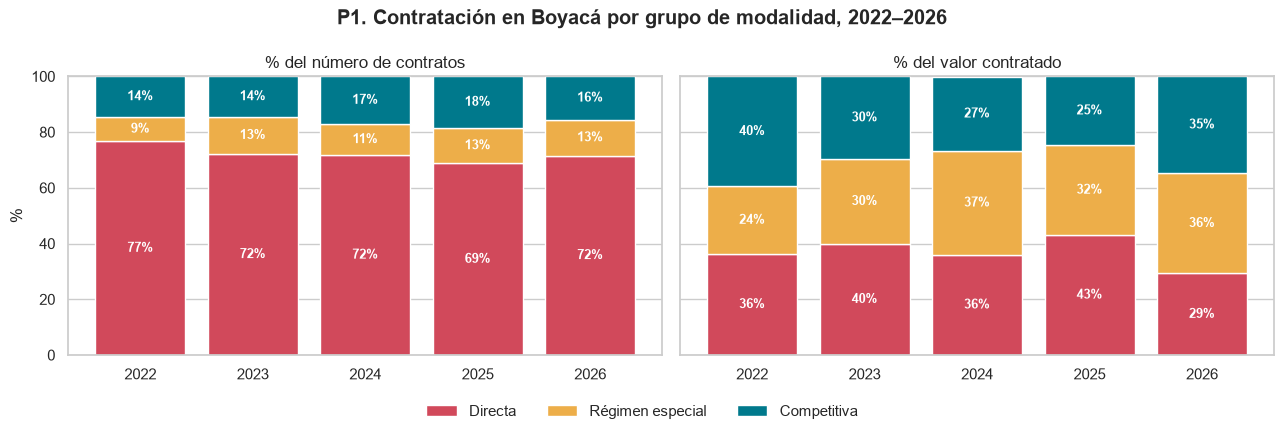

In [24]:
orden = ["Directa", "Régimen especial", "Competitiva"]
colores = {"Directa": "#d1495b", "Régimen especial": "#edae49", "Competitiva": "#00798c"}
piv_n = p1_pd.pivot(index="anio", columns="grupo_modalidad", values="pct_contratos")[orden]
piv_v = p1_pd.pivot(index="anio", columns="grupo_modalidad", values="pct_valor")[orden]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, piv, titulo in [(axes[0], piv_n, "% del número de contratos"), (axes[1], piv_v, "% del valor contratado")]:
    abajo = np.zeros(len(piv))
    for g in orden:
        ax.bar(piv.index.astype(str), piv[g], bottom=abajo, color=colores[g], label=g)
        for x, (b, h) in enumerate(zip(abajo, piv[g])):
            if h > 6:
                ax.text(x, b + h/2, f"{h:.0f}%", ha="center", va="center", color="white", fontsize=9, weight="bold")
        abajo += piv[g].to_numpy()
    ax.set_title(titulo); ax.set_ylim(0, 100)
axes[0].set_ylabel("%")
manejadores, etiquetas = axes[0].get_legend_handles_labels()
fig.legend(manejadores, etiquetas, loc="lower center", ncol=3, frameon=False)
fig.suptitle("P1. Contratación en Boyacá por grupo de modalidad, 2022–2026", weight="bold")
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

### P2 · Entidades que más dependen de la contratación directa (Plotly)

In [25]:
top_ent = p2_pd.head(15).sort_values("pct_valor_directa")
fig = px.bar(top_ent, x="pct_valor_directa", y="nombre_entidad", orientation="h",
             color="valor_total_mm", color_continuous_scale="Reds",
             hover_data={"contratos": True, "pct_contratos_directa": True},
             labels={"pct_valor_directa": "% del valor por contratación directa", "nombre_entidad": "",
                     "valor_total_mm": "Valor total<br>(miles de M)", "pct_contratos_directa": "% contratos directos"},
             title="P2. Top 15 entidades (≥ $20.000 M contratados) por % de valor en contratación directa")
fig.update_layout(height=560, margin=dict(l=10, r=10, t=60, b=10))
fig.show()

### P3 · Ley de Garantías: serie mensual (Plotly)

In [26]:
mensual = (df.groupby("anio_mes")
             .agg(contratos=("id_contrato", "count"),
                  directas=("grupo_modalidad", lambda s: (s == "Directa").sum()))
             .reset_index())
mensual["pct_directa"] = 100 * mensual["directas"] / mensual["contratos"]
mensual = mensual[mensual["anio_mes"] < df["anio_mes"].max()]   # se excluye el mes en curso (incompleto)

fig = go.Figure()
fig.add_bar(x=mensual["anio_mes"], y=mensual["contratos"], name="Contratos firmados", marker_color="#b8c4cc", yaxis="y")
fig.add_scatter(x=mensual["anio_mes"], y=mensual["pct_directa"], name="% contratación directa",
                mode="lines+markers", line=dict(color="#d1495b", width=3), yaxis="y2")
for ini, fin in VENTANAS:
    fig.add_vrect(x0=ini, x1=fin, fillcolor="#edae49", opacity=0.18, line_width=0,
                  annotation_text="Ley de Garantías", annotation_position="top left")
fig.update_layout(title="P3. Contratos firmados por mes y % de contratación directa",
                  yaxis=dict(title="Contratos firmados"),
                  yaxis2=dict(title="% directa", overlaying="y", side="right", range=[0, 100]),
                  legend=dict(orientation="h", y=-0.15), height=460)
fig.show()

In [27]:
# Cuantificación del efecto en los años electorales: antes, durante y después de la ventana.
# Se usan contratos por DÍA porque los periodos tienen duraciones distintas.
periodos = [
    (2022, "1. Antes",   "2022-01-01", "2022-01-28"),
    (2022, "2. Durante", "2022-01-29", "2022-06-19"),
    (2022, "3. Después", "2022-06-20", "2022-12-31"),
    (2026, "1. Antes",   "2026-01-01", "2026-01-30"),
    (2026, "2. Durante", "2026-01-31", "2026-06-21"),
    (2026, "3. Después", "2026-06-22", "2026-10-31"),
]
filas = []
for anio, nombre, ini, fin in periodos:
    d = df[df["fecha_de_firma"].between(ini, f"{fin} 23:59:59")]
    dias = (pd.Timestamp(fin) - pd.Timestamp(ini)).days + 1
    filas.append({"año": anio, "periodo": nombre, "días": dias, "contratos": len(d),
                  "contratos_por_día": len(d) / dias,
                  "directas_por_día": (d["grupo_modalidad"] == "Directa").sum() / dias,
                  "% directa": 100 * (d["grupo_modalidad"] == "Directa").mean()})
efecto = pd.DataFrame(filas).set_index(["año", "periodo"])
display(efecto.round(1))

# En 2022 la caída no empieza el 29 de enero sino días después: se revisa día a día
d = df[df["fecha_de_firma"].between("2022-01-27", "2022-02-09")]
dia = d.groupby(d["fecha_de_firma"].dt.date).agg(contratos=("id_contrato", "size"),
                                                pct_directa=("grupo_modalidad", lambda s: round(100 * (s == "Directa").mean())))
display(dia.T)

# ¿El pico de enero es normal o es anticipación? Se compara enero de años electorales y no electorales
ene = (df.assign(es_enero=df["mes"] == 1)
         .groupby("anio")
         .agg(contratos_enero=("es_enero", "sum"), contratos_anio=("id_contrato", "count")))
ene["% del año firmado en enero"] = 100 * ene["contratos_enero"] / ene["contratos_anio"]
ene["año electoral (presidencial)"] = ene.index.isin([2022, 2026])
ene.round(1)

días  contratos  contratos_por_día  directas_por_día  % directa
año  periodo                                                                    
2022 1. Antes      28       5051             180.40            177.00      98.10
     2. Durante   142       2355              16.60             10.10      60.60
     3. Después   195       7295              37.40             25.10      67.10
2026 1. Antes      30      13960             465.30            415.50      89.30
     2. Durante   142       3809              26.80              1.70       6.50
     3. Después   132      11603              87.90             63.20      71.90

fecha_de_firma,2022-01-27,2022-01-28,2022-01-29,2022-01-30,2022-01-31,2022-02-01,2022-02-02,2022-02-03,2022-02-04,2022-02-05,2022-02-07,2022-02-08
contratos,606,976,50,23,58,133,630,424,7,2,4,12
pct_directa,99,99,100,100,69,94,99,99,14,100,25,8


,contratos_enero,contratos_anio,% del año firmado en enero,año electoral (presidencial)
anio,,,,
2022,5182,14701,35.20,True
2023,2595,19918,13.00,False
2024,2244,28681,7.80,False
2025,4563,31474,14.50,False
2026,14107,29660,47.60,True


### P3 · Patrón mensual por año (Seaborn)

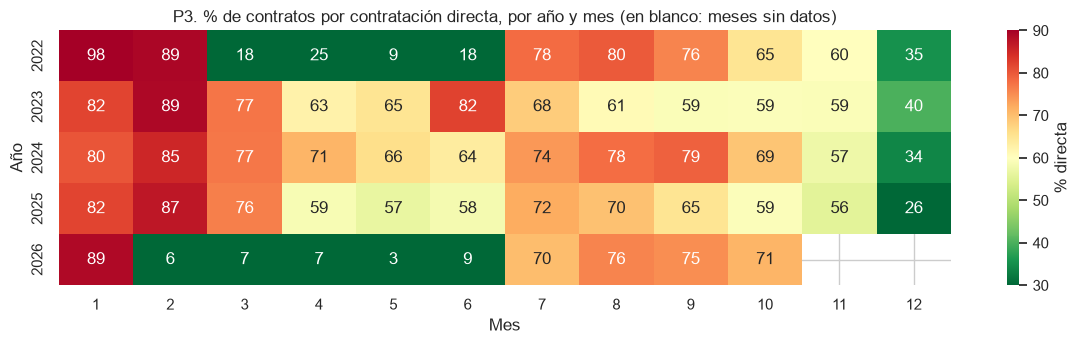

In [28]:
heat = (df[df["anio_mes"] < df["anio_mes"].max()]
          .pivot_table(index="anio", columns="mes", values="grupo_modalidad",
                       aggfunc=lambda s: 100 * (s == "Directa").mean()))
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn_r", vmin=30, vmax=90, cbar_kws={"label": "% directa"}, ax=ax)
ax.set_title("P3. % de contratos por contratación directa, por año y mes (en blanco: meses sin datos)")
ax.set_xlabel("Mes"); ax.set_ylabel("Año")
plt.tight_layout(); plt.show()

### P4 · Tipo de contrato, tipo de proveedor y valores (Seaborn + Plotly)

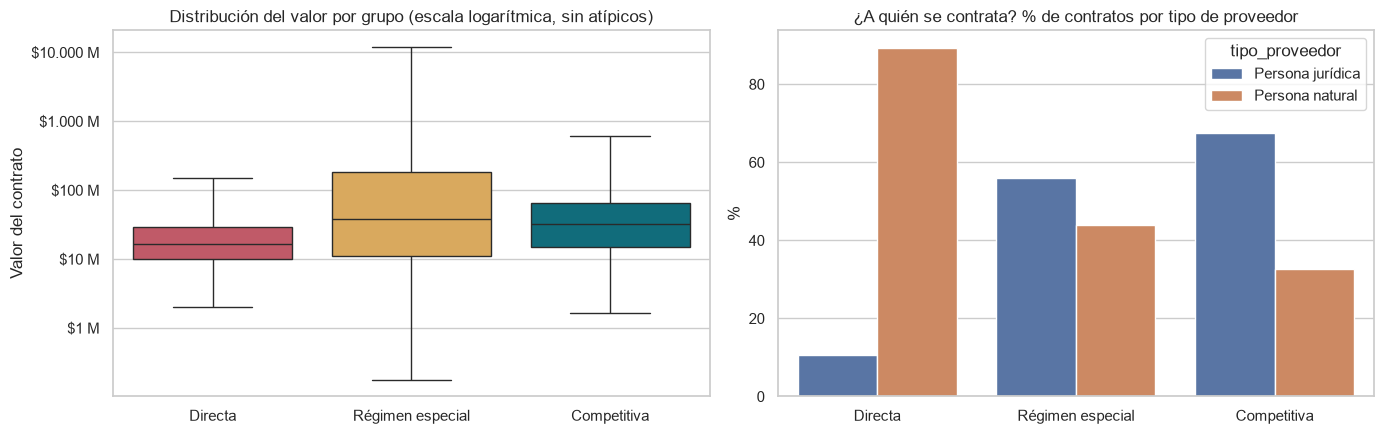

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
box = df.loc[df["valor_valido"], ["grupo_modalidad", "valor_analisis"]].assign(log_valor=lambda d: np.log10(d["valor_analisis"]))
sns.boxplot(data=box, x="grupo_modalidad", y="log_valor", order=orden, palette=colores, showfliers=False, ax=axes[0])
marcas = [6, 7, 8, 9, 10]
axes[0].set_yticks(marcas, ["$1 M", "$10 M", "$100 M", "$1.000 M", "$10.000 M"])
axes[0].set_title("Distribución del valor por grupo (escala logarítmica, sin atípicos)")
axes[0].set_xlabel(""); axes[0].set_ylabel("Valor del contrato")

tp = (df.groupby("grupo_modalidad")["tipo_proveedor"].value_counts(normalize=True)
        .mul(100).rename("pct").reset_index())
sns.barplot(data=tp, x="grupo_modalidad", y="pct", hue="tipo_proveedor", order=orden, ax=axes[1])
axes[1].set_title("¿A quién se contrata? % de contratos por tipo de proveedor"); axes[1].set_xlabel(""); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

In [30]:
directa = df[(df["grupo_modalidad"] == "Directa") & df["valor_valido"]]
tree = (directa.groupby(["tipo_de_contrato", "tipo_proveedor"])["valor_analisis"].sum() / 1e9).reset_index(name="valor_mm")
fig = px.treemap(tree, path=[px.Constant("Contratación directa"), "tipo_de_contrato", "tipo_proveedor"],
                 values="valor_mm", color="valor_mm", color_continuous_scale="Reds",
                 title="P4. ¿En qué se gasta la contratación directa? (valor en miles de millones)")
fig.update_traces(texttemplate="%{label}<br>$%{value:,.0f} mil M")
fig.update_layout(height=480, margin=dict(t=50, l=5, r=5, b=5))
fig.show()

In [31]:
# Concentración: curva de Lorenz y coeficiente de Gini del valor de la contratación directa por proveedor
por_prov = np.sort(directa.groupby("id_proveedor")["valor_analisis"].sum().to_numpy())
acum = np.cumsum(por_prov) / por_prov.sum()
x = np.arange(1, por_prov.size + 1) / por_prov.size
gini = 1 - 2 * np.trapezoid(acum, x)
top1 = 1 - acum[int(0.99 * por_prov.size) - 1]

fig = go.Figure()
fig.add_scatter(x=x * 100, y=acum * 100, name="Curva de Lorenz", line=dict(color="#d1495b", width=3))
fig.add_scatter(x=[0, 100], y=[0, 100], name="Igualdad perfecta", line=dict(dash="dash", color="gray"))
fig.update_layout(title=f"P4. Concentración del valor de la contratación directa entre {por_prov.size:,} proveedores "
                        f"(Gini = {gini:.2f}; el 1 % de proveedores recibe el {top1*100:.0f} % del valor)",
                  xaxis_title="% acumulado de proveedores", yaxis_title="% acumulado del valor", height=430)
fig.show()

## 7. Conclusiones y recomendaciones

### Respuestas a las preguntas

**P1 · ¿Cuánto pesa la contratación directa?** Es la forma dominante de contratar en Boyacá. Cada año entre el **69 % y el 77 % de los contratos** se firman por contratación directa, y solo entre el 14 % y el 19 % pasan por una modalidad competitiva. En **valor**, el peso es menor, entre el **29 % y el 43 %**, porque los contratos directos son pequeños: su mediana es de unos $16 millones, frente a unos $32 millones en las modalidades competitivas. No hay una tendencia clara a la baja: 2025 fue el año con mayor participación de la directa en el valor (43 %).

**P2 · ¿Qué entidades dependen más de ella?** Entre las 66 entidades que contrataron al menos $20.000 millones, la **Gobernación de Boyacá** es la de mayor gasto y adjudica por directa el **96 % de sus contratos y el 69 % de su valor**. Le siguen el ITBOY, la Alcaldía de Puerto Boyacá, el SENA regional y Corpoboyacá, todas con más del 59 % del valor por directa. Las alcaldías de Tunja, Duitama y Sogamoso rondan el 47–48 % del valor.

**P3 · ¿Funciona la Ley de Garantías?** Sí, y con mucha fuerza, pero produce un **efecto de anticipación**:
- En 2026, durante la ventana restrictiva, la contratación directa cayó de **415 contratos por día a menos de 2**, y su participación pasó del 89 % al **6,5 %**. Después de la segunda vuelta subió de nuevo a 63 por día (72 %).
- Justo antes de que empezara la restricción, las entidades firmaron **14.107 contratos en enero de 2026**, el 48 % de todo lo firmado en 2026 hasta la fecha de descarga. En un año sin elecciones, enero pesa mucho menos: 4.563 contratos en 2025 (15 % del año) y 2.244 en 2024 (8 %). En 2022 pasó lo mismo: enero concentró el 35 % del año. Es decir, la restricción no elimina la contratación directa, sino que **la adelanta**.
- En 2022 los datos muestran que la caída real empezó el **4 de febrero**, no el 29 de enero: entre el 29 de enero y el 3 de febrero se registraron más de 1.200 contratos, casi todos directos. Puede tratarse de contratos ya adjudicados con firma electrónica posterior; es un punto que conviene verificar en SECOP.

**P4 · ¿Qué explica la contratación directa?** El **88 %** de los contratos directos son **prestación de servicios con personas naturales** (apoyo a la gestión y servicios profesionales). El valor, en cambio, se concentra mucho: el **coeficiente de Gini es 0,79** y el **1 % de los proveedores recibe el 56 % del valor** de la contratación directa. Ese 1 % incluye sobre todo operaciones que no son "favoritismo" por sí mismas, como créditos con bancos y convenios con otras entidades públicas. En municipios pequeños, como Arcabuco, Briceño o Chitaraque, un solo proveedor recibe más del 40 % del valor contratado por directa.

### Recomendaciones

1. **Para veedurías y concejos:** priorizar el seguimiento de las entidades con más del 60 % del valor por directa y de los municipios donde un solo proveedor concentra más del 40 % de esa contratación. El dashboard permite filtrarlas.
2. **Vigilar enero en años electorales:** el pico de firmas antes de la Ley de Garantías es el momento de mayor riesgo. Revisar si esos contratos son necesarios o si buscan "blindar" la nómina de contratistas antes de la restricción.
3. **Para las entidades:** muchos contratos de apoyo a la gestión son recurrentes año tras año. Si corresponden a funciones permanentes, conviene evaluar su paso a planta de personal.
4. **Para Colombia Compra Eficiente:** mejorar la validación de los datos en origen. Hay contratos de valor imposible (un suministro de \$2,4 billones), cientos con valor \$0 y miles sin ciudad, lo que dificulta el control ciudadano.

### Limitaciones

- SECOP II no incluye lo publicado en SECOP I ni en la Tienda Virtual del Estado, así que el total de contratación de algunas entidades es mayor.
- La contratación directa no es ilegal por sí misma: el análisis mide su peso, no si cada contrato estaba justificado.
- Se excluyeron de las sumas de valor 772 contratos (0,6 %) con valor menor a \$10.000 o mayor a \$50.000 millones, por ser errores de registro, valores simbólicos u operaciones no comparables.

## Declaración del uso de IA

| Herramienta | Tarea | Qué se verificó o corrigió |
|---|---|---|
| Claude (Anthropic) | Búsqueda del dataset de SECOP II y armado de la consulta filtrada a la API; borrador de la estructura del notebook y del código de PySpark, MongoDB, Streaming y Streamlit; redacción inicial de las conclusiones. | Se ejecutó el notebook completo en un equipo Windows local con Java 21, MongoDB real en Docker (61.134 documentos insertados) y Spark Structured Streaming (12 micro-lotes), sin errores; se configuró Hadoop (winutils) para Windows; se verificó que Spark y pandas leen los mismos 124.434 registros; se desplegó y probó el dashboard en Streamlit Community Cloud con distintos filtros. |

In [32]:
spark.stop()
print("Fin del notebook.")

Fin del notebook.
